# Hotel Review Sentiment Analysis

We compare **TF-IDF + Logistic Regression** with **pretrained RoBERTa**.
The input is an English hotel review and the output is Positive or Negative.

Our main question is: which method has a higher macro F1 on reviews containing
negation, such as "not clean" or "wasn't bad"?

Run the cells in order using the project Python environment (see `README.md`).
If `Datafiniti_Hotel_Reviews.csv` is missing, the notebook downloads it from Kaggle.
The first run needs an internet connection for the dataset and RoBERTa model.
This notebook uses the same experiment choices as the earlier final version,
but the code and explanations are shorter.

## 1. Import libraries

Pandas handles the reviews, scikit-learn provides our first model and evaluation,
and Transformers/PyTorch run RoBERTa. Results are saved in the `results_student` folder.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SEED = 42
labels = ['Negative', 'Positive']
results_dir = Path('results_student')
results_dir.mkdir(exist_ok=True)

C:\Users\ezio9\Desktop\Courses\Natural Language Processing - 9MA1\NLP_PROJ\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load and clean the reviews

Remove missing/blank text and invalid ratings. Ratings from 1 to 2 are Negative,
and 4 to 5 are Positive. Remove 3-star and other middle ratings without rounding.

For duplicate checking only, normalize spaces, case, Unicode, and apostrophes.
If duplicate text has opposite labels, remove that whole group. Otherwise keep
one copy. We still give the original trimmed review text to the models.

In [2]:
data_path = Path('Datafiniti_Hotel_Reviews.csv')
if not data_path.exists():
    print('Downloading hotel reviews from Kaggle...')
    url = 'https://www.kaggle.com/api/v1/datasets/download/datafiniti/hotel-reviews'
    with urlopen(url, timeout=120) as response:
        with ZipFile(BytesIO(response.read())) as archive:
            data_path.write_bytes(archive.read(data_path.name))

df = pd.read_csv(data_path, usecols=['reviews.text', 'reviews.rating'])
df['source_row'] = df.index
df = df.rename(columns={'reviews.text': 'text', 'reviews.rating': 'rating'})
print('Original reviews:', len(df))

df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df = df.dropna(subset=['text', 'rating']).copy()
df['text'] = df['text'].astype(str).str.strip()
df = df[df['text'] != ''].copy()
df = df[df['rating'].between(1, 2) | df['rating'].between(4, 5)].copy()
df['label'] = np.where(df['rating'] <= 2, 'Negative', 'Positive')

def clean_duplicate_text(text):
    text = unicodedata.normalize('NFKC', text).replace('’', "'")
    return ' '.join(text.casefold().split())

df['duplicate_key'] = df['text'].apply(clean_duplicate_text)
label_counts = df.groupby('duplicate_key')['label'].transform('nunique')
df = df[label_counts == 1].copy()
df = df.drop_duplicates(subset='duplicate_key').reset_index(drop=True)

print('Cleaned reviews:', len(df))
display(df['label'].value_counts().reindex(labels))
display(df[['text', 'rating', 'label']].head())

Original reviews: 10000
Cleaned reviews: 8422


label
Negative    1152
Positive    7270
Name: count, dtype: int64

,text,rating,label
0,Our experience at Rancho Valencia was absolute...,5.0,Positive
1,Amazing place. Everyone was extremely warm and...,5.0,Positive
2,We booked a 3 night stay at Rancho Valencia to...,5.0,Positive
3,Currently in bed writing this for the past hr ...,2.0,Negative
4,I live in Md and the Aloft is my Home away fro...,5.0,Positive


## 3. Mark negation and split the data

Fix our negation list before testing: no, not, never, neither, nor, without,
cannot, and contractions ending in n't (straight or curly apostrophe).
Word boundaries prevent matching these words inside unrelated words.
This finds negation words, but does not tell us their scope or meaning.

Use 70% for training, 15% for development, and 15% for testing. Stratification
keeps similar label proportions. Seed 42 makes the split repeatable.

,Split,Reviews,Negative,Positive,With negation
0,Training,5895,806,5089,2537
1,Development,1263,173,1090,556
2,Test,1264,173,1091,542


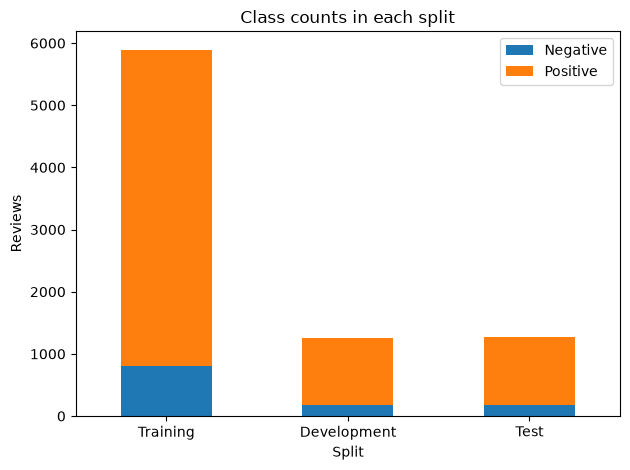

In [3]:
negation_pattern = r"\b(?:no|not|never|neither|nor|without|cannot)\b|\b\w+n['\u2019]t\b"
df['has_negation'] = df['text'].str.contains(negation_pattern, case=False, regex=True)

train_df, remaining_df = train_test_split(
    df, test_size=0.30, stratify=df['label'], random_state=SEED
)
dev_df, test_df = train_test_split(
    remaining_df, test_size=0.50, stratify=remaining_df['label'], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
dev_df = dev_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_rows = []
for name, part in [('Training', train_df), ('Development', dev_df), ('Test', test_df)]:
    split_rows.append({
        'Split': name, 'Reviews': len(part),
        'Negative': (part['label'] == 'Negative').sum(),
        'Positive': (part['label'] == 'Positive').sum(),
        'With negation': part['has_negation'].sum()
    })
split_summary = pd.DataFrame(split_rows)
display(split_summary)
split_summary.to_csv(results_dir / 'split_summary.csv', index=False)

# Check that the same review never appears in two splits.
assert set(train_df['duplicate_key']).isdisjoint(dev_df['duplicate_key'])
assert set(train_df['duplicate_key']).isdisjoint(test_df['duplicate_key'])
assert set(dev_df['duplicate_key']).isdisjoint(test_df['duplicate_key'])

split_summary.set_index('Split')[labels].plot.bar(stacked=True, rot=0)
plt.ylabel('Reviews')
plt.title('Class counts in each split')
plt.tight_layout()
plt.show()

## 4. TF-IDF + Logistic Regression

TF-IDF turns review words into numbers. Unigrams are single words and bigrams
are pairs like "not clean". Keep stop words and contractions because negation matters.

Try six settings: C = 0.1, 1, 10, with and without balanced class weights.
Fit each pipeline only on training data. Pick the highest development macro F1.
For ties, keep the first setting. Do not refit or choose settings using the test set.

In [4]:
best_f1 = -1
lr_rows = []

for c in [0.1, 1, 10]:
    for weight in [None, 'balanced']:
        model = Pipeline([
            ('tfidf', TfidfVectorizer(
                ngram_range=(1, 2), stop_words=None,
                token_pattern=r"(?u)\b\w+(?:['\u2019]\w+)?\b",
                min_df=2, max_features=50000, sublinear_tf=True
            )),
            ('lr', LogisticRegression(
                C=c, class_weight=weight, solver='liblinear',
                max_iter=2000, random_state=SEED
            ))
        ])
        model.fit(train_df['text'], train_df['label'])
        dev_pred = model.predict(dev_df['text'])
        score = f1_score(dev_df['label'], dev_pred, labels=labels,
                         average='macro', zero_division=0)
        lr_rows.append({'C': c, 'Class weight': weight, 'Dev macro F1': score})
        if score > best_f1:
            best_f1 = score
            best_lr = model
            best_c = c
            best_weight = weight

lr_search = pd.DataFrame(lr_rows)
display(lr_search)
lr_search.to_csv(results_dir / 'lr_development_search.csv', index=False)
print('Selected C:', best_c, '| Class weight:', best_weight)

,C,Class weight,Dev macro F1
0,0.1,None,0.463238
1,0.1,balanced,0.829946
2,1.0,None,0.712998
3,1.0,balanced,0.862973
4,10.0,None,0.859081
5,10.0,balanced,0.876866


Selected C: 10 | Class weight: balanced


## 5. Load pretrained RoBERTa

Use `cardiffnlp/twitter-roberta-base-sentiment` without training its weights.
Its output order is Negative, Neutral, Positive. Use the GPU if available,
otherwise use the CPU. The fixed model revision keeps the model version repeatable.

RoBERTa keeps the first 512 tokens including special tokens. TF-IDF uses the full
review, so truncation is a limitation. The first run downloads the model;
later runs can use the cache.

In [5]:
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batch_size = 16 if device.type == 'cuda' else 8
print('Device:', device)

model_name = 'cardiffnlp/twitter-roberta-base-sentiment'
revision = 'daefdd1f6ae931839bce4d0f3db0a1a4265cd50f'
tokenizer = AutoTokenizer.from_pretrained(
    model_name, revision=revision, cache_dir='.cache/huggingface'
)
roberta = AutoModelForSequenceClassification.from_pretrained(
    model_name, revision=revision, cache_dir='.cache/huggingface'
).to(device)
tokenizer.truncation_side = 'right'
roberta.eval()

def get_roberta_scores(texts):
    texts = list(texts)
    rows = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        full_tokens = tokenizer(batch, truncation=False, verbose=False)['input_ids']
        inputs = tokenizer(batch, padding=True, truncation=True,
                           max_length=512, return_tensors='pt').to(device)
        with torch.no_grad():
            logits = roberta(**inputs).logits
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            # Equivalent to P(Positive) / (P(Positive) + P(Negative)).
            positive_scores = torch.softmax(logits[:, [0, 2]], dim=1)[:, 1].cpu().numpy()
        for i in range(len(batch)):
            rows.append({
                'p_negative': probs[i, 0], 'p_neutral': probs[i, 1],
                'p_positive': probs[i, 2], 'positive_score': positive_scores[i],
                'truncated': len(full_tokens[i]) > 512
            })
        if start % (batch_size * 40) == 0:
            print('Scored', min(start + batch_size, len(texts)), 'of', len(texts))
    return pd.DataFrame(rows)

Device: cpu


C:\Users\ezio9\Desktop\Courses\Natural Language Processing - 9MA1\NLP_PROJ\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ezio9\Desktop\Courses\Natural Language Processing - 9MA1\NLP_PROJ\.cache\huggingface\models--cardiffnlp--twitter-roberta-base-sentiment. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


## 6. Choose RoBERTa's cutoff on development data

Convert the three-class output to a binary score:
`P(Positive) / (P(Positive) + P(Negative))`.
This discards neutral probability, so it can make mixed reviews look more certain.
We keep the original probabilities too.

Try cutoffs from 0.05 to 0.95 in steps of 0.01. Choose the highest development macro
F1. Ties prefer the cutoff closest to 0.5, then the smaller cutoff.
Keep this single cutoff for both negation groups. All settings are final after this cell.

In [6]:
dev_scores = get_roberta_scores(dev_df['text'])
cutoff_rows = []
for cutoff in np.round(np.arange(0.05, 0.951, 0.01), 2):
    pred = np.where(dev_scores['positive_score'] >= cutoff, 'Positive', 'Negative')
    score = f1_score(dev_df['label'], pred, labels=labels, average='macro', zero_division=0)
    cutoff_rows.append({'Cutoff': cutoff, 'Dev macro F1': score,
                        'Distance from 0.5': round(abs(cutoff - 0.5), 2)})

cutoff_search = pd.DataFrame(cutoff_rows)
cutoff_search = cutoff_search.sort_values(
    ['Dev macro F1', 'Distance from 0.5', 'Cutoff'], ascending=[False, True, True]
)
best_cutoff = float(cutoff_search.iloc[0]['Cutoff'])
display(cutoff_search.head())
cutoff_search.to_csv(results_dir / 'roberta_development_cutoffs.csv', index=False)
print('Selected RoBERTa cutoff:', best_cutoff)
print('Truncated development reviews:', dev_scores['truncated'].sum())

Scored 8 of 1263


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Scored 328 of 1263


Scored 648 of 1263


Scored 968 of 1263


,Cutoff,Dev macro F1,Distance from 0.5
19,0.24,0.863372,0.26
22,0.27,0.862696,0.23
21,0.26,0.862696,0.24
20,0.25,0.862024,0.25
23,0.28,0.861358,0.22


Selected RoBERTa cutoff: 0.24
Truncated development reviews: 3


## 7. Evaluate on the test set

The baseline always predicts the most common training label.
All methods use the same test reviews. Accuracy measures the fraction correct.
Macro F1 gives Negative and Positive equal weight, which matters because Positive
reviews are more common. Report both metrics for all reviews and each negation group.
Do not adjust the models after seeing these results.

In [7]:
majority_label = train_df['label'].value_counts().idxmax()
test_scores = get_roberta_scores(test_df['text'])

test_results = test_df[['source_row', 'text', 'rating', 'label', 'has_negation']].copy()
test_results['Majority baseline'] = majority_label
test_results['TF-IDF + Logistic Regression'] = best_lr.predict(test_df['text'])
test_results['RoBERTa'] = np.where(
    test_scores['positive_score'] >= best_cutoff, 'Positive', 'Negative'
)
positive_index = list(best_lr.classes_).index('Positive')
test_results['lr_positive_score'] = best_lr.predict_proba(test_df['text'])[:, positive_index]
for column in test_scores.columns:
    test_results['roberta_' + column] = test_scores[column].to_numpy()

methods = ['Majority baseline', 'TF-IDF + Logistic Regression', 'RoBERTa']
groups = {
    'All reviews': test_results,
    'With negation': test_results[test_results['has_negation']],
    'Without negation': test_results[~test_results['has_negation']]
}
metric_rows = []
for group_name, part in groups.items():
    for method in methods:
        metric_rows.append({
            'Group': group_name, 'Model': method, 'Reviews': len(part),
            'Negative': (part['label'] == 'Negative').sum(),
            'Positive': (part['label'] == 'Positive').sum(),
            'Accuracy': accuracy_score(part['label'], part[method]) if len(part) else np.nan,
            'Macro F1': f1_score(part['label'], part[method], labels=labels,
                                  average='macro', zero_division=0) if len(part) else np.nan
        })
metrics = pd.DataFrame(metric_rows)
display(metrics.round(4))
print('Truncated test reviews:', test_scores['truncated'].sum())
metrics.to_csv(results_dir / 'test_metrics.csv', index=False)
test_results.to_csv(results_dir / 'test_predictions.csv', index=False)

Scored 8 of 1264


Scored 328 of 1264


Scored 648 of 1264


Scored 968 of 1264


,Group,Model,Reviews,Negative,Positive,Accuracy,Macro F1
0,All reviews,Majority baseline,1264,173,1091,0.8631,0.4633
1,All reviews,TF-IDF + Logistic Regression,1264,173,1091,0.9462,0.8888
2,All reviews,RoBERTa,1264,173,1091,0.9320,0.8553
3,With negation,Majority baseline,542,139,403,0.7435,0.4265
4,With negation,TF-IDF + Logistic Regression,542,139,403,0.9133,0.8886
5,With negation,RoBERTa,542,139,403,0.8967,0.8632
6,Without negation,Majority baseline,722,34,688,0.9529,0.4879
7,Without negation,TF-IDF + Logistic Regression,722,34,688,0.9709,0.8402
8,Without negation,RoBERTa,722,34,688,0.9584,0.7748


Truncated test reviews: 3


## 8. Plot the results

Compare the overall scores, then show where each method makes mistakes.

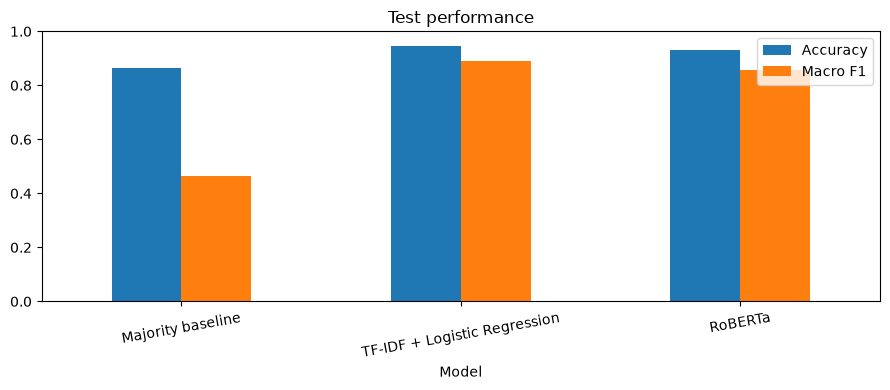

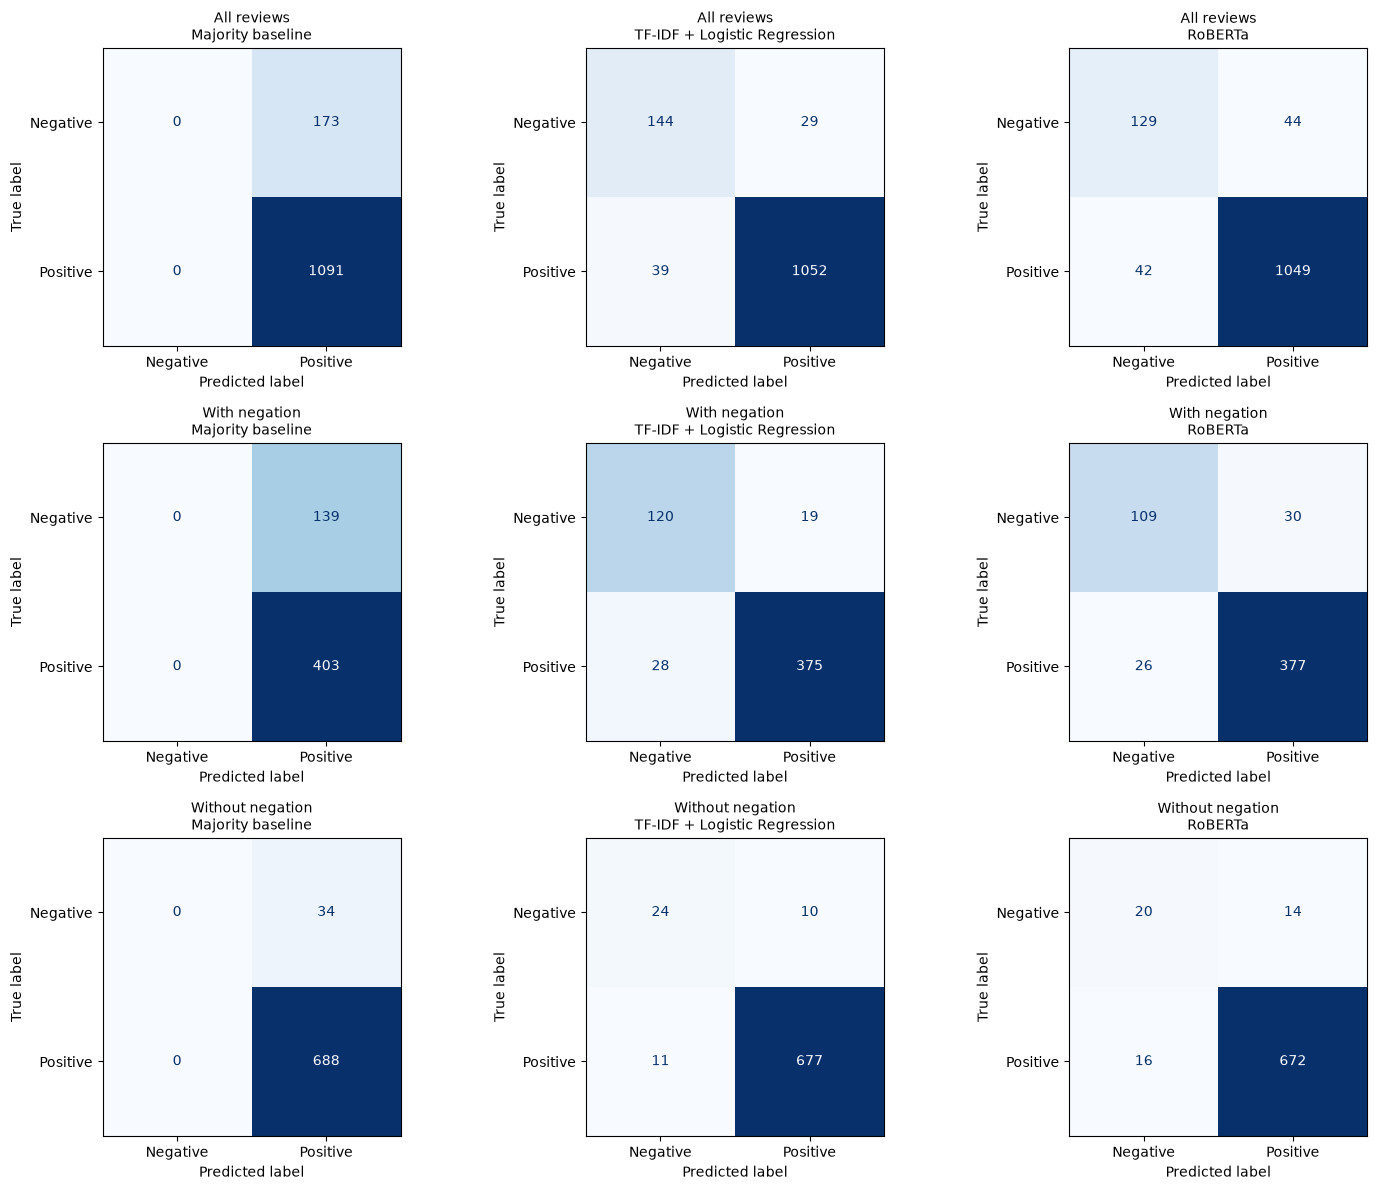

In [8]:
overall = metrics[metrics['Group'] == 'All reviews'].set_index('Model')
overall[['Accuracy', 'Macro F1']].plot.bar(figsize=(9, 4), ylim=(0, 1), rot=10)
plt.title('Test performance')
plt.tight_layout()
plt.savefig(results_dir / 'test_comparison.png', dpi=150)
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for i, (group_name, part) in enumerate(groups.items()):
    for j, method in enumerate(methods):
        if len(part) == 0:
            axes[i, j].set_title(group_name + ': no reviews')
            axes[i, j].set_axis_off()
            continue
        cm = confusion_matrix(part['label'], part[method], labels=labels)
        ConfusionMatrixDisplay(cm, display_labels=labels).plot(
            ax=axes[i, j], colorbar=False, cmap='Blues', values_format='d'
        )
        axes[i, j].set_title(group_name + '\n' + method, fontsize=10)
plt.tight_layout()
plt.savefig(results_dir / 'confusion_matrices.png', dpi=150)
plt.show()

## 9. Look at incorrect predictions

Show three real test errors from each method, preferring two negation examples.
The actual label comes from the rating, so a wrong prediction can also reveal
a mismatch between the text and the overall rating. The explanations below are
possible explanations, not proven reasons for the models' decisions.

In [9]:
error_parts = []
for method in methods[1:]:
    errors = test_results[test_results[method] != test_results['label']].sort_values('source_row')
    negation_errors = errors[errors['has_negation']].head(2)
    examples = pd.concat([negation_errors, errors.drop(index=negation_errors.index)]).head(3)
    print(method, ':', len(errors), 'errors; showing', len(examples))
    for _, row in examples.iterrows():
        print('\nSource row:', row['source_row'])
        print('Review:', row['text'])
        print('Rating:', row['rating'], '| Actual:', row['label'], '| Predicted:', row[method])
        print('Contains negation:', row['has_negation'])
    examples = examples[['source_row', 'text', 'rating', 'label', 'has_negation', method]].copy()
    examples = examples.rename(columns={method: 'Prediction'})
    examples['Model'] = method
    error_parts.append(examples)

error_examples = pd.concat(error_parts, ignore_index=True)
error_examples.to_csv(results_dir / 'error_examples.csv', index=False)

TF-IDF + Logistic Regression : 68 errors; showing 3

Source row: 508
Review: Good: Staff was rude to me and didn't recognize my platinum status
Rating: 1.9 | Actual: Negative | Predicted: Positive
Contains negation: True

Source row: 587
Review: Bad: Even though we asked to have the room cleaned they only folded the towels..had to ask for clean cups and coffee!. Good: No smoking hotel...love the beds!
Rating: 4.4 | Actual: Positive | Predicted: Negative
Contains negation: True

Source row: 785
Review: Good: THE HOTEL NEEDS A BETTER COFFEE SHOP FOR QUICK BREAKFAST. WHAT EXISTS THERE IS ONLY OKAY...IT IS NOT INVITING OR OFFERS MUCH WARMTH.
Rating: 4.6 | Actual: Positive | Predicted: Negative
Contains negation: True
RoBERTa : 86 errors; showing 3

Source row: 563
Review: Bad: No bathroom vent.
Rating: 4.4 | Actual: Positive | Predicted: Negative
Contains negation: True

Source row: 572
Review: Bad: Not a fan of cigarette smoke. But I guess you can't do anything about it in the gambling ar

These examples use the same dataset and split as the original experiment.
If you change either, check the printed errors again.

| Source row / model | Observed text and label | Possible explanation ? not a verified model cause |
|---|---|---|
| 508 / Logistic Regression | The text begins with a `Good:` marker but complains about rude staff and failure to recognize loyalty status. Rating 1.9 gives Negative; prediction is Positive. | The marker may contribute a positive word feature despite the complaint. Inspecting feature contributions would be needed to check that hypothesis. |
| 587 / Logistic Regression | Housekeeping complaints are followed by praise for the beds and a non-smoking hotel. Rating 4.4 gives Positive; prediction is Negative. | Complaint-related features may outweigh the praise. The negation match in the non-smoking description can concern a desirable hotel attribute, so a negation match does not by itself mean negative sentiment. |
| 785 / Logistic Regression | The review criticizes the coffee shop and its lack of warmth, despite a `Good:` marker and a 4.6 rating. The prediction is Negative. | The text and the overall star rating may emphasize different aspects. A negative reading of this excerpt is plausible; the rating-derived label has not been manually corrected. |
| 563 / RoBERTa | A short complaint about the absence of a bathroom vent has rating 4.4. Actual binary label is Positive; prediction is Negative. | A local complaint can coexist with a positive overall rating. Possible rating/text disagreement limits what this example can establish about negation handling. |
| 572 / RoBERTa | Complaints about smoke and resort fees precede praise for helpful staff. Rating 5 gives Positive; prediction is Negative. | The complaint section may dominate the decision, or the overall rating may give more weight to the staff. No attribution or causal analysis was performed. |
| 548 / RoBERTa | The text describes an old hotel needing refurbishment and also praises value for money. Rating 4.15 gives Positive; prediction is Negative. This review has no fixed-list negation match. | Competing aspects and a rating/text difference may explain the disagreement. This example shows that mistakes also occur without a detected negation cue. |

## 10. Try a new review

After running the earlier cells, edit `new_review` and run this cell again.
Both methods return a label and the binary probability assigned to that label,
without retraining. This confidence is not a guarantee of correctness.
With RoBERTa's tuned cutoff, the selected label can have a probability below 0.5.

In [10]:
new_review = 'The room was not clean, but the staff were helpful.'
if not new_review.strip():
    raise ValueError('Please enter a review.')

lr_score = best_lr.predict_proba([new_review])[0, positive_index]
new_scores = get_roberta_scores([new_review]).iloc[0]
roberta_score = float(new_scores['positive_score'])

demo_rows = []
for method, score, cutoff in [
    ('TF-IDF + Logistic Regression', lr_score, 0.5),
    ('RoBERTa', roberta_score, best_cutoff)
]:
    prediction = 'Positive' if score >= cutoff else 'Negative'
    demo_rows.append({'Model': method, 'Prediction': prediction,
                      'Confidence': score if prediction == 'Positive' else 1 - score,
                      'Positive score': score, 'Cutoff': cutoff})
display(pd.DataFrame(demo_rows).round(4))
print('RoBERTa neutral probability:', round(float(new_scores['p_neutral']), 4))
print('Review truncated:', new_scores['truncated'])

Scored 1 of 1


,Model,Prediction,Confidence,Positive score,Cutoff
0,TF-IDF + Logistic Regression,Negative,0.5452,0.4548,0.50
1,RoBERTa,Positive,0.9623,0.9623,0.24


RoBERTa neutral probability: 0.2216
Review truncated: False


## 11. Conclusion and limitations

Use the measured results above to answer our research question. A higher score on
this split does not prove a method is always better.

- Positive reviews dominate, so compare macro F1 as well as accuracy.
- Ratings are approximate sentiment labels; mixed reviews can disagree with their ratings.
- RoBERTa was trained for tweet sentiment, which differs from hotel reviews.
- The binary score discards RoBERTa's neutral probability.
- Long reviews may be truncated for RoBERTa.
- Negation matching finds words, not their meaning or scope. The groups also have
  different class balances, so their score differences are not caused only by negation.
- Exact normalized duplicates are removed, but near duplicates and reviews from
  the same hotel may still appear in different splits.
- This is one random split, and English is expected but not automatically checked.

The report and presentation should include the methods, actual counts, result table,
negation comparison, at least three error explanations, limitations, and references.

Sources: [Datafiniti](https://www.kaggle.com/datasets/datafiniti/hotel-reviews),
[RoBERTa model](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment),
[TweetEval](https://aclanthology.org/2020.findings-emnlp.148/),
[original repository](https://github.com/mohaiyaaldossary/hotel-review-sentiment-analysis).